In [1]:
# Interfaz
import re
import textwrap
import traceback
from datetime import datetime
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipyfilechooser import FileChooser
from IPython.display import clear_output, display
from matplotlib.backends.backend_pdf import PdfPages

import Funciones
import NNMF_GIF as NMF
import NNMF_GIF2 as CONMF
from MetricasRendimiento import MetricasRendimiento

%config InlineBackend.figure_format = 'svg'

#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5

def procesar_archivo(nombre, carpeta_base, vocal, parametros):
    try:
        ruta_archivo = Path(carpeta_base) / nombre
        df = pd.read_csv(ruta_archivo, sep=',')

        fs_r = 8000
        tiempos = df['t_ms'].values
        t0_analisis = 5 #ms
        tf_analisis = 45#ms
        mascara_tiempos = (tiempos >= t0_analisis) & (tiempos <= tf_analisis)
        tiempos_analisis = tiempos[mascara_tiempos]

        parametros["CONMF"]["mascara_tiempos"] = mascara_tiempos
        parametros["NMF_speech"]["mascara_tiempos"] = mascara_tiempos
        parametros["NMF_acc"]["mascara_tiempos"] = mascara_tiempos
        # ==================================================================
        señal_MBK  = df['MBK'].values
        señal_MBK  = señal_MBK - np.mean(señal_MBK)
        if parametros["Filtro_pb_inicial_speech"]["aplicar"]:
                señal_MBK,_,_     = Funciones.LP_Filter(señal_MBK, fs=fs_r, fc=parametros["Filtro_pb_inicial_speech"]["fc"], order=parametros["Filtro_pb_inicial_speech"]["orden"])
        señal_ACC  = -df['ACC'].values
        señal_ACC  = señal_ACC - np.mean(señal_ACC)
        señal_EGG = df['MBK'].values
        señal_EGG = Funciones.Detrend(tiempos, señal_EGG)
        señal_dEGG = np.gradient(señal_EGG)

        flujo_OVV   = df['flujo_OVV'].values[mascara_tiempos]
        flujo_OVV  = Funciones.Normalizar(flujo_OVV)
        dflujo_OVV = np.gradient(flujo_OVV)
        dflujo_OVV = Funciones.NormalizarDflujo(dflujo_OVV)
        # ==============================================================================================================================================================
        resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK,
                    acelerometro=señal_ACC,
                    dEGG = señal_dEGG,
                    tiempos=tiempos,
                    mascara_tiempos = parametros["CONMF"]["mascara_tiempos"],
                    fs=fs_r,
                    norma=parametros["CONMF"]["norma"],
                    pre_iteraciones=parametros["CONMF"]["pre_iteraciones"],
                    iteraciones=parametros["CONMF"]["iteraciones"],
                    T = parametros["CONMF"]["T"],
                    delta = parametros["CONMF"]["delta"],
                    p_filtro_speech=parametros["CONMF"]["p_filtro_speech"],
                    alfa_speech=parametros["CONMF"]["alfa_speech"],
                    p_filtro_acc=parametros["CONMF"]["p_filtro_acc"],
                    alfa_acc=parametros["CONMF"]["alfa_acc"],
                    beta_speech=parametros["CONMF"]["beta_speech"],
                    beta_acc= parametros["CONMF"]["beta_acc"],
                    pre_enfasis_speech=parametros["CONMF"]["pre_enfasis_speech"],
                    pre_enfasis_acc=parametros["CONMF"]["pre_enfasis_acc"],
                    doble_pre_enfasis_acc = parametros["CONMF"]["doble_pre_enfasis_acc"],
                    duracion=parametros["CONMF"]["duracion"],
                    guardar_proceso=parametros["CONMF"]["guardar_proceso"],
                    normalizar_espectrogramas=parametros["CONMF"]["normalizar_espectrogramas"],
                    ventana = parametros["CONMF"]["ventana"]
        )

        
        resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK,
                                            dEGG = señal_dEGG,
                                            tiempos=tiempos,
                                            mascara_tiempos = parametros["NMF_speech"]["mascara_tiempos"],
                                            fs=fs_r,
                                            norma=parametros["NMF_speech"]["norma"],
                                            pre_iteraciones=parametros["NMF_speech"]["pre_iteraciones"],
                                            iteraciones=parametros["NMF_speech"]["iteraciones"],
                                            T = parametros["NMF_speech"]["T"],
                                            delta = parametros["NMF_speech"]["delta"],
                                            p_filtro=parametros["NMF_speech"]["p_filtro"],
                                            alfa=parametros["NMF_speech"]["alfa"],
                                            beta=parametros["NMF_speech"]["beta"],
                                            pre_enfasis=parametros["NMF_speech"]["pre_enfasis"],
                                            duracion=parametros["NMF_speech"]["duracion"],
                                            guardar_proceso=parametros["NMF_speech"]["guardar_proceso"],
                                            ventana = parametros["NMF_speech"]["ventana"]
                                            )

        resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC,
                                            dEGG = señal_dEGG,
                                            tiempos=tiempos,
                                            mascara_tiempos = parametros["NMF_acc"]["mascara_tiempos"],
                                            fs=fs_r,
                                            norma=parametros["NMF_acc"]["norma"],
                                            pre_iteraciones=parametros["NMF_acc"]["pre_iteraciones"],
                                            iteraciones=parametros["NMF_acc"]["iteraciones"],
                                            T = parametros["NMF_acc"]["T"],
                                            delta = parametros["NMF_acc"]["delta"],
                                            p_filtro=parametros["NMF_acc"]["p_filtro"],
                                            alfa=parametros["NMF_acc"]["alfa"],
                                            beta=parametros["NMF_acc"]["beta"],
                                            pre_enfasis=parametros["NMF_acc"]["pre_enfasis"],
                                            doble_pre_enfasis=parametros["NMF_acc"]["doble_pre_enfasis"],
                                            duracion=parametros["NMF_acc"]["duracion"],
                                            guardar_proceso=parametros["NMF_acc"]["guardar_proceso"],
                                            ventana = parametros["NMF_acc"]["ventana"]
                                            )
        
        
        # Filtrado pasabajos final
        if parametros["Filtro_pb_final"]["aplicar"]:
            if vocal == 'A':
                orden_filtro_pb = parametros["Filtro_pb_final"]["A"]["orden"]
                fc_filtro_pb    =  parametros["Filtro_pb_final"]["A"]["fc"]
            else:
                orden_filtro_pb = parametros["Filtro_pb_final"]["I"]["orden"]
                fc_filtro_pb    = parametros["Filtro_pb_final"]["I"]["fc"]
            resultado_NMF_speech.flujo1, _, _ = Funciones.LP_Filter(resultado_NMF_speech.flujo1, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_speech.flujo1 = Funciones.Normalizar(resultado_NMF_speech.flujo1)
            resultado_NMF_speech.flujo2, _, _ = Funciones.LP_Filter(resultado_NMF_speech.flujo2, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_speech.flujo2 = Funciones.Normalizar(resultado_NMF_speech.flujo2)

            resultado_NMF_speech.dflujo1, _, _ = Funciones.LP_Filter(resultado_NMF_speech.dflujo1, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_speech.dflujo1 = Funciones.NormalizarDflujo(resultado_NMF_speech.dflujo1)
            resultado_NMF_speech.dflujo2, _, _ = Funciones.LP_Filter(resultado_NMF_speech.dflujo2, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_speech.dflujo2 = Funciones.NormalizarDflujo(resultado_NMF_speech.dflujo2)

            resultado_NMF_acc.flujo1, _, _ = Funciones.LP_Filter(resultado_NMF_acc.flujo1, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_acc.flujo1 = Funciones.Normalizar(resultado_NMF_acc.flujo1)
            resultado_NMF_acc.flujo2, _, _ = Funciones.LP_Filter(resultado_NMF_acc.flujo2, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_acc.flujo2 = Funciones.Normalizar(resultado_NMF_acc.flujo2)       

            resultado_NMF_acc.dflujo1, _, _ = Funciones.LP_Filter(resultado_NMF_acc.dflujo1, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_acc.dflujo1 = Funciones.NormalizarDflujo(resultado_NMF_acc.dflujo1)
            resultado_NMF_acc.dflujo2, _, _ = Funciones.LP_Filter(resultado_NMF_acc.dflujo2, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_NMF_acc.dflujo2 = Funciones.NormalizarDflujo(resultado_NMF_acc.dflujo2)

            resultado_CONMF.flujo1_speech,_,_ = Funciones.LP_Filter(resultado_CONMF.flujo1_speech, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_CONMF.flujo1_speech = Funciones.Normalizar(resultado_CONMF.flujo1_speech)
            resultado_CONMF.flujo2_speech,_,_ = Funciones.LP_Filter(resultado_CONMF.flujo2_speech, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_CONMF.flujo2_speech = Funciones.Normalizar(resultado_CONMF.flujo2_speech)

            resultado_CONMF.dflujo1_speech,_,_ = Funciones.LP_Filter(resultado_CONMF.dflujo1_speech, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_CONMF.dflujo1_speech = Funciones.NormalizarDflujo(resultado_CONMF.dflujo1_speech)       
            resultado_CONMF.dflujo2_speech,_,_ = Funciones.LP_Filter(resultado_CONMF.dflujo2_speech, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb) 
            resultado_CONMF.dflujo2_speech = Funciones.NormalizarDflujo(resultado_CONMF.dflujo2_speech)

            resultado_CONMF.flujo1_acc,_,_ = Funciones.LP_Filter(resultado_CONMF.flujo1_acc, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_CONMF.flujo1_acc = Funciones.Normalizar(resultado_CONMF.flujo1_acc)
            resultado_CONMF.flujo2_acc,_,_ = Funciones.LP_Filter(resultado_CONMF.flujo2_acc, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_CONMF.flujo2_acc = Funciones.Normalizar(resultado_CONMF.flujo2_acc)
                    
            resultado_CONMF.dflujo1_acc,_,_ = Funciones.LP_Filter(resultado_CONMF.dflujo1_acc, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_CONMF.dflujo1_acc = Funciones.NormalizarDflujo(resultado_CONMF.dflujo1_acc)
            resultado_CONMF.dflujo2_acc,_,_ = Funciones.LP_Filter(resultado_CONMF.dflujo2_acc, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            resultado_CONMF.dflujo2_acc = Funciones.NormalizarDflujo(resultado_CONMF.dflujo2_acc) 
        # ==================================================================
        ''' 
        # Configuración del filtrado post-procesamiento (depende de la vocal)
        filtro_cfg = parametros["Filtro_pb_final"]
        aplicar_filtro = filtro_cfg["aplicar"]

        if vocal == 'A':
            orden_filtro_pb = filtro_cfg["A"]["orden"]
            fc_filtro_pb    = filtro_cfg["A"]["fc"]
        else:
            orden_filtro_pb = filtro_cfg["I"]["orden"]
            fc_filtro_pb    = filtro_cfg["I"]["fc"]

        def filtrar_flujo(flujo):
            """Aplica (o no) el filtro pasabajos configurado y recalcula la derivada."""
            if aplicar_filtro:
                flujo_filtrado, _, _ = Funciones.LP_Filter(flujo, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
            else:
                flujo_filtrado = flujo
            dflujo_filtrado = np.gradient(flujo_filtrado)
            return flujo_filtrado, dflujo_filtrado

        # ==================================================================
        # CONMF
        resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK, acelerometro=señal_ACC, dEGG=señal_dEGG, tiempos=tiempos, fs=fs_r, **parametros["CONMF"])
        
        resultado_CONMF.flujo1_speech, resultado_CONMF.dflujo1_speech = filtrar_flujo(resultado_CONMF.flujo1_speech)
        #resultado_CONMF.flujo1_speech  = Funciones.Detrend(resultado_CONMF.tiempos_gve_speech,resultado_CONMF.flujo1_speech)
        resultado_CONMF.flujo1_speech  = Funciones.Normalizar(resultado_CONMF.flujo1_speech)
        resultado_CONMF.dflujo1_speech = np.gradient(resultado_CONMF.flujo1_speech)
        
        resultado_CONMF.flujo1_acc, resultado_CONMF.dflujo1_acc       = filtrar_flujo(resultado_CONMF.flujo1_acc)
        #resultado_CONMF.flujo1_acc     = Funciones.Detrend(resultado_CONMF.tiempos_gve_acc,resultado_CONMF.flujo1_acc)
        resultado_CONMF.flujo1_acc     = Funciones.Normalizar(resultado_CONMF.flujo1_acc)  
        resultado_CONMF.dflujo1_acc    = np.gradient(resultado_CONMF.flujo1_acc)
        # ==================================================================
        # NMF SPEECH
        resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK, dEGG=señal_dEGG, tiempos=tiempos, fs=fs_r, **parametros["NMF_speech"])
        resultado_NMF_speech.flujo1, resultado_NMF_speech.dflujo1 = filtrar_flujo(resultado_NMF_speech.flujo1)
        #resultado_NMF_speech.flujo1 = Funciones.Detrend(resultado_NMF_speech.tiempos_gve,resultado_NMF_speech.flujo1)
        resultado_NMF_speech.flujo1 = Funciones.Normalizar(resultado_NMF_speech.flujo1)
        resultado_NMF_speech.dflujo1 = np.gradient(resultado_NMF_speech.flujo1)
        # ==================================================================
        # NMF ACC
        resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC, dEGG=señal_dEGG, tiempos=tiempos, fs=fs_r, **parametros["NMF_acc"])
        resultado_NMF_acc.flujo1, resultado_NMF_acc.dflujo1 = filtrar_flujo(resultado_NMF_acc.flujo1)
        #resultado_NMF_acc.flujo1 = Funciones.Detrend(resultado_NMF_acc.tiempos_gve,resultado_NMF_acc.flujo1)
        resultado_NMF_acc.flujo1 = Funciones.Normalizar(resultado_NMF_acc.flujo1)    
        resultado_NMF_acc.dflujo1 = np.gradient(resultado_NMF_acc.flujo1)
        '''
        # ==================================================================
        # METRICAS
        # tipo_error: 'flujo'  -> error calculado sobre el flujo glótico
        #             'dflujo' -> error calculado sobre la función glótica (derivada del flujo)
        tipo_error = parametros["tipo_error"]

        if tipo_error == 'flujo':
            referencia          = flujo_OVV
            señal_NMF_speech     = resultado_NMF_speech.flujo1
            señal_NMF_acc        = resultado_NMF_acc.flujo1
            señal_CONMF_speech   = resultado_CONMF.flujo1_speech
            señal_CONMF_acc      = resultado_CONMF.flujo1_acc
        else:
            referencia           = dflujo_OVV
            señal_NMF_speech     = resultado_NMF_speech.dflujo1
            señal_NMF_acc        = resultado_NMF_acc.dflujo1
            señal_CONMF_speech   = resultado_CONMF.dflujo1_speech
            señal_CONMF_acc      = resultado_CONMF.dflujo1_acc

        MR_NMF_speech_1   = MetricasRendimiento(referencia, señal_NMF_speech, tiempos_analisis)
        MR_NMF_acc_1      = MetricasRendimiento(referencia, señal_NMF_acc, tiempos_analisis)
        MR_CONMF_speech_1 = MetricasRendimiento(referencia, señal_CONMF_speech, tiempos_analisis)
        MR_CONMF_acc_1    = MetricasRendimiento(referencia, señal_CONMF_acc, tiempos_analisis)

        '''
        Prueba de Error I
        MR_NMF_speech_1   = MetricasRendimiento(señal_NMF_speech, señal_NMF_acc, tiempos_analisis)
        MR_NMF_acc_1      = MetricasRendimiento(señal_NMF_speech, señal_NMF_acc, tiempos_analisis)
        MR_CONMF_speech_1 = MetricasRendimiento(señal_CONMF_speech, señal_CONMF_acc, tiempos_analisis)
        MR_CONMF_acc_1    = MetricasRendimiento(señal_CONMF_speech, señal_CONMF_acc, tiempos_analisis)
        '''
        '''
        Prueba de Error II
        MR_NMF_speech_1   = MetricasRendimiento(señal_NMF_speech, señal_CONMF_speech, tiempos_analisis)
        MR_NMF_acc_1      = MetricasRendimiento(señal_NMF_acc, señal_CONMF_acc, tiempos_analisis)
        MR_CONMF_speech_1 = MetricasRendimiento(señal_NMF_speech, señal_CONMF_speech, tiempos_analisis)
        MR_CONMF_acc_1    = MetricasRendimiento(señal_NMF_acc, señal_CONMF_acc, tiempos_analisis)
        '''
        
        return {
            "archivo": nombre,
            "ok": True,
            "NMF_speech": MR_NMF_speech_1.Error,
            "NMF_acc": MR_NMF_acc_1.Error,
            "CONMF_speech": MR_CONMF_speech_1.Error,
            "CONMF_acc": MR_CONMF_acc_1.Error,
        }

    except Exception as e:
        return {
            "archivo": nombre,
            "ok": False,
            "error": f"{type(e).__name__}: {e}",
            "traceback": traceback.format_exc(),
        }

def _tabla(ax, filas, columnas, col_widths, row_h=0.05, fontsize=8):
    """Dibuja una tabla con encabezado azul, filas alternadas y texto con saltos de línea."""
    ax.axis("off")

    filas_wrap, lineas = [], []
    for fila in filas:
        celdas = [textwrap.fill(str(c), width=max(int(w * 110), 10)) for c, w in zip(fila, col_widths)]
        filas_wrap.append(celdas)
        lineas.append(max(c.count("\n") + 1 for c in celdas))

    tabla = ax.table(
        cellText=filas_wrap,
        colLabels=columnas,
        colWidths=col_widths,
        loc="upper center",
        cellLoc="left",
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(fontsize)

    for (i, j), celda in tabla.get_celld().items():
        n = 1 if i == 0 else lineas[i - 1]
        celda.set_height(row_h * n)
        if i == 0:
            celda.set_facecolor("#4C72B0")
            celda.set_text_props(color="white", weight="bold")
        elif i % 2 == 0:
            celda.set_facecolor("#F0F0F0")


def figura_info(vocal1, vocal2, lista1, lista2, total_archivos, archivos_fallidos,
                tipo_error, modo,parametros):
    """Página con dos tablas: información general y parámetros CONMF vs NMF."""
    fig = plt.figure(figsize=(8.27, 11.69))  # A4
    gs = fig.add_gridspec(2, 1, height_ratios=[1, 2.8], hspace=0.05,
                          left=0.06, right=0.94, top=0.95, bottom=0.04)
    ax_info = fig.add_subplot(gs[0])
    ax_par = fig.add_subplot(gs[1])

    # ---------------- Tabla 1: información general ----------------
    if parametros["Filtro_pb_final"]["aplicar"]:
        txt_filtro_pb_final = (f"Aplicado. /a/: orden={parametros["Filtro_pb_final"]['A']['orden']}, fc={parametros["Filtro_pb_final"]['A']['fc']} Hz | "
                      f"/i/: orden={parametros["Filtro_pb_final"]['I']['orden']}, fc={parametros["Filtro_pb_final"]['I']['fc']} Hz")
    else:
        txt_filtro_pb_final = "No aplicado"
    if parametros["Filtro_pb_inicial_speech"]["aplicar"]:
        txt_filtro_pb_inicial = (f"Aplicado. Orden={parametros["Filtro_pb_inicial_speech"]["orden"]}, fc={parametros["Filtro_pb_inicial_speech"]["fc"]} Hz")
    else:
        txt_filtro_pb_inicial = "No aplicado"

    txt_ventanas = str(total_archivos)
    if archivos_fallidos:
        txt_ventanas += f" (fallaron {len(archivos_fallidos)})"

    filas_info = [
        [f"Archivo 1 (vocal /{vocal1.lower()}/)", lista1.name.removesuffix(".txt")],
        [f"Archivo 2 (vocal /{vocal2.lower()}/)", lista2.name.removesuffix(".txt")],
        ["Ventanas analizadas", txt_ventanas],
        ["Error calculado sobre", "Flujo glótico" if tipo_error == "flujo" else "Función glótica"],
        ["Agrupamiento del boxplot", "Conjunto (todas las señales)" if modo == "conjunto" else "Separado por vocal (/a/ vs /i/)"],
        ["Filtrado pasabajos incial speech", txt_filtro_pb_inicial],
        ["Filtrado pasabajos final", txt_filtro_pb_final],
    ]
    _tabla(ax_info, filas_info, ["Información", "Valor"], [0.32, 0.68], row_h=0.12)
    ax_info.set_title("Información general", fontsize=13, weight="bold")

    # ---------------- Tabla 2: parámetros CONMF vs NMF ----------------
    c = parametros["CONMF"]
    ns = parametros["NMF_speech"]
    na = parametros["NMF_acc"]

    filas_par = [
        ["Norma", c["norma"], ns["norma"]],
        ["Ventana", c["ventana"], ns["ventana"]],
        ["Duración ventana [ms]", c["duracion"], ns["duracion"]],
        ["Pre-iteraciones", c["pre_iteraciones"], ns["pre_iteraciones"]],
        ["Iteraciones", c["iteraciones"], ns["iteraciones"]],
        ["T (criterio de parada)", c["T"], ns["T"]],
        ["Delta", c["delta"], ns["delta"]],
        ["Orden filtro speech (p)", c["p_filtro_speech"], ns["p_filtro"]],
        ["Alfa speech", c["alfa_speech"], ns["alfa"]],
        ["Beta speech", c["beta_speech"], ns["beta"]],
        ["Pre-énfasis speech", c["pre_enfasis_speech"], ns["pre_enfasis"]],
        ["Orden filtro acc (p)", c["p_filtro_acc"], na["p_filtro"]],
        ["Alfa acc", c["alfa_acc"], na["alfa"]],
        ["Beta acc", c["beta_acc"], na["beta"]],
        ["Pre-énfasis acc", c["pre_enfasis_acc"], na["pre_enfasis"]],
        ["Doble pre-énfasis acc", c["doble_pre_enfasis_acc"], na["doble_pre_enfasis"]],
        ["Guardar proceso", c["guardar_proceso"], ns["guardar_proceso"]],
        ["Normalizar espectrogramas", c["normalizar_espectrogramas"], "—"],
    ]
    _tabla(ax_par, filas_par, ["Parámetro", "CONMF", "NMF"], [0.5, 0.25, 0.25], row_h=0.045, fontsize=9)
    ax_par.set_title("Parámetros utilizados", fontsize=13, weight="bold")

    return fig


def figura_fallidos(archivos_fallidos):
    """Página extra (solo si hubo archivos fallidos)."""
    fig = plt.figure(figsize=(8.27, 11.69))
    ax = fig.add_axes([0.06, 0.04, 0.88, 0.9])
    filas = [[f["archivo"], f["error"]] for f in archivos_fallidos]
    _tabla(ax, filas, ["Archivo", "Error"], [0.4, 0.6], row_h=0.03)
    ax.set_title("Archivos fallidos", fontsize=13, weight="bold")
    return fig
#========================================================================================================================================
def _limpiar(lista):
    """Convierte a array de numpy y descarta NaN."""
    arr = np.array(lista, dtype=float)
    return arr[~np.isnan(arr)]

#========================================================================================================================================
def ejecutar(b):

    global resultados_errores
    global archivos_fallidos

    # ==============================================================
    # Vocal asignada a cada archivo (elegida por el usuario, sin asumir un orden fijo)

    vocal1 = vocal_archivo1.value
    vocal2 = vocal_archivo2.value

    if vocal1 == vocal2:
        with tab_boxplots:
            clear_output(wait=True)
            print("Error: los dos archivos tienen la misma vocal asignada (deben ser 'A' e 'I', una para cada uno).")
        return

    # Estructura de resultados indexada por vocal, no por posición del archivo,
    # de forma que sea indistinto si /a/ se cargó como archivo 1 o como archivo 2.
    resultados_errores = {
        'A': {'NMF_speech': [], 'NMF_acc': [], 'CONMF_speech': [], 'CONMF_acc': []},
        'I': {'NMF_speech': [], 'NMF_acc': [], 'CONMF_speech': [], 'CONMF_acc': []},
    }
    archivos_fallidos = []

    # ==============================================================

    lista_señales1 = Path(fc1.selected)
    lista_señales2 = Path(fc2.selected)
    carpeta_base1 = lista_señales1.parent
    carpeta_base2 = lista_señales2.parent

    with open(lista_señales1, "r", encoding="utf-8") as f:
        nombres_archivos1 = [linea.strip() for linea in f if linea.strip()]

    with open(lista_señales2, "r", encoding="utf-8") as f:
        nombres_archivos2 = [linea.strip() for linea in f if linea.strip()]

    total_archivos = len(nombres_archivos1) + len(nombres_archivos2)
    barra_progreso.max = total_archivos
    barra_progreso.value = 0

    label_progreso.value = f'0/{total_archivos}'

    # ==============================================================
    parametros = {
        "CONMF": {
            "norma": conmf_norma.value,
            "pre_iteraciones": conmf_pre_iteraciones.value,
            "iteraciones": conmf_iteraciones.value,
            "T": conmf_T.value,
            "delta": conmf_delta.value,
            "p_filtro_speech": conmf_p_filtro_speech.value,
            "alfa_speech": conmf_alfa_speech.value,
            "p_filtro_acc": conmf_p_filtro_acc.value,
            "alfa_acc": conmf_alfa_acc.value,
            "beta_speech": conmf_beta_speech.value,
            "beta_acc": conmf_beta_acc.value,
            "pre_enfasis_speech": conmf_pre_enfasis_speech.value,
            "pre_enfasis_acc": conmf_pre_enfasis_acc.value,
            "doble_pre_enfasis_acc":conmf_doble_pre_enfasis_acc.value,
            "duracion": conmf_duracion_ventana.value,
            "guardar_proceso": conmf_guardar_proceso.value,
            "normalizar_espectrogramas": conmf_normalizar_espectrogramas.value,
            "ventana": conmf_ventana.value
        },
        "NMF_speech": {
            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "T": nmf_T.value,
            "delta": nmf_delta.value,
            "p_filtro": nmf_p_filtro_speech.value,
            "alfa": nmf_alfa_speech.value,
            "beta": nmf_beta_speech.value,
            "pre_enfasis": nmf_pre_enfasis_speech.value,
            "doble_pre_enfasis": False,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        },
        "NMF_acc": {
            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "T": nmf_T.value,
            "delta": nmf_delta.value,
            "p_filtro": nmf_p_filtro_acc.value,
            "alfa": nmf_alfa_acc.value,
            "beta": nmf_beta_acc.value,
            "pre_enfasis": nmf_pre_enfasis_acc.value,
            "doble_pre_enfasis": nmf_doble_pre_enfasis_acc.value,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        },
        # --------------------------------------------------------------
        # Filtrado
        "Filtro_pb_inicial_speech":{
            "aplicar":filtro_pb_inicial.value,
            "fc": filtro_pb_inicial_fc.value,
            "orden": filtro_pb_inicial_orden.value
        },
        "Filtro_pb_final": {
            "aplicar": filtro_pb_final.value,
            "A": {
                "orden": filtro_orden_A.value,
                "fc": filtro_fc_A.value,
            },
            "I": {
                "orden": filtro_orden_I.value,
                "fc": filtro_fc_I.value,
            },
        },
        # --------------------------------------------------------------
        # Sobre qué señal se calcula el error: 'flujo' o 'dflujo'
        "tipo_error": tipo_error_dropdown.value,
    }

    # ==============================================================
    # Ejecuto las tareas de forma secuencial (bucle for, sin Ray).
    # Se procesa primero toda la lista 1 (con vocal1) y después toda la
    # lista 2 (con vocal2), igual que antes. Si un archivo falla, se
    # informa y se continúa con el siguiente en vez de cortar todo.

    procesados = 0
    nombres_señales_a = []
    for nombre in nombres_archivos1:
        resultado = procesar_archivo(nombre, str(carpeta_base1), vocal1, parametros)

        if not resultado["ok"]:
            print(f"⚠️ Falló {resultado['archivo']}: {resultado['error']}")
            archivos_fallidos.append(resultado)
        else:
            resultados_errores[vocal1]['CONMF_speech'].append(resultado["CONMF_speech"])
            resultados_errores[vocal1]['CONMF_acc'].append(resultado["CONMF_acc"])
            resultados_errores[vocal1]['NMF_speech'].append(resultado["NMF_speech"])
            resultados_errores[vocal1]['NMF_acc'].append(resultado["NMF_acc"])
            nombres_señales_a.append(nombre)

        procesados += 1
        barra_progreso.value = procesados
        label_progreso.value = (f'{procesados}/{total_archivos}')

    nombres_señales_i = []
    for nombre in nombres_archivos2:
        resultado = procesar_archivo(nombre, str(carpeta_base2), vocal2, parametros)

        if not resultado["ok"]:
            print(f"⚠️ Falló {resultado['archivo']}: {resultado['error']}")
            archivos_fallidos.append(resultado)
        else:
            resultados_errores[vocal2]['CONMF_speech'].append(resultado["CONMF_speech"])
            resultados_errores[vocal2]['CONMF_acc'].append(resultado["CONMF_acc"])
            resultados_errores[vocal2]['NMF_speech'].append(resultado["NMF_speech"])
            resultados_errores[vocal2]['NMF_acc'].append(resultado["NMF_acc"])
            nombres_señales_i.append(nombre)
        procesados += 1
        barra_progreso.value = procesados
        label_progreso.value = (f'{procesados}/{total_archivos}')

    if archivos_fallidos:
        print(f"\nTotal de archivos fallidos: {len(archivos_fallidos)} de {total_archivos}")

    with tab_boxplots:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(12, 6))
        color_NMF = "#0505058F"
        color_CONMF = "#79FF74"

        modo = modo_agrupamiento.value  # 'separado' o 'conjunto'

        if modo == 'separado':
            # El orden de graficado (/a/ primero, /i/ segundo) queda fijo,
            # independientemente de qué archivo se haya asignado a cada vocal.
            datos = [
                # Vocal A para el speech
                _limpiar(resultados_errores['A']['NMF_speech']),
                _limpiar(resultados_errores['A']['CONMF_speech']),

                # Vocal I para el speech
                _limpiar(resultados_errores['I']['NMF_speech']),
                _limpiar(resultados_errores['I']['CONMF_speech']),

                # Vocal A para el acc
                _limpiar(resultados_errores['A']['NMF_acc']),
                _limpiar(resultados_errores['A']['CONMF_acc']),

                # Vocal I para el acc
                _limpiar(resultados_errores['I']['NMF_acc']),
                _limpiar(resultados_errores['I']['CONMF_acc']),
                
            ]
            datos_csv = [
                # Vocal A para el speech
                _limpiar(resultados_errores['A']['NMF_speech']),
                _limpiar(resultados_errores['A']['CONMF_speech']),
                # Vocal A para el acc
                _limpiar(resultados_errores['A']['NMF_acc']),
                _limpiar(resultados_errores['A']['CONMF_acc']),
                nombres_señales_a,
                # Vocal I para el speech
                _limpiar(resultados_errores['I']['NMF_speech']),
                _limpiar(resultados_errores['I']['CONMF_speech']),
                # Vocal I para el acc
                _limpiar(resultados_errores['I']['NMF_acc']),
                _limpiar(resultados_errores['I']['CONMF_acc']),
                nombres_señales_i,
                
            ]

            labels = ['/a/', '/i/', '/a/', '/i/']
            algos = ['NMF', 'CONMF', 'NMF', 'CONMF', 'NMF', 'CONMF', 'NMF', 'CONMF']
            columnas_csv = [
                'NMF_speech_a', 'CONMF_speech_a',
                'NMF_acc_a', 'CONMF_acc_a',
                "Señales A",
                'NMF_speech_i', 'CONMF_speech_i',
                'NMF_acc_i', 'CONMF_acc_i',
                "Señales I"
            ]

            pair_gap = 0.2
            group_gap = 1.0
            block_gap = 1.6

            pair_centers = [
                1.0,
                1.0 + group_gap,
                1.0 + group_gap + block_gap,
                1.0 + 2 * group_gap + block_gap
            ]

            positions = []
            for c in pair_centers:
                positions += [c - pair_gap, c + pair_gap]

        else:
            # Modo conjunto: se combinan los resultados de ambas vocales
            # (/a/ e /i/) en una única distribución por algoritmo y tipo de señal.
            datos = [
                _limpiar(resultados_errores['A']['NMF_speech'] + resultados_errores['I']['NMF_speech']),
                _limpiar(resultados_errores['A']['CONMF_speech'] + resultados_errores['I']['CONMF_speech']),
                _limpiar(resultados_errores['A']['NMF_acc'] + resultados_errores['I']['NMF_acc']),
                _limpiar(resultados_errores['A']['CONMF_acc'] + resultados_errores['I']['CONMF_acc']),
            ]
            datos_csv = [
                _limpiar(resultados_errores['A']['NMF_speech'] + resultados_errores['I']['NMF_speech']),
                _limpiar(resultados_errores['A']['CONMF_speech'] + resultados_errores['I']['CONMF_speech']),
                _limpiar(resultados_errores['A']['NMF_acc'] + resultados_errores['I']['NMF_acc']),
                _limpiar(resultados_errores['A']['CONMF_acc'] + resultados_errores['I']['CONMF_acc']),
                nombres_señales_a+nombres_señales_i
            ]

            labels = ['Speech', 'Speech', 'ACC', 'ACC']
            algos = ['NMF', 'CONMF', 'NMF', 'CONMF']
            columnas_csv = ['NMF_speech', 'CONMF_speech', 'NMF_acc', 'CONMF_acc',"Señal"]

            pair_gap = 0.2
            block_gap = 1.6

            pair_centers = [1.0, 1.0 + block_gap]

            positions = []
            for c in pair_centers:
                positions += [c - pair_gap, c + pair_gap]

        bp = ax.boxplot(
            datos,
            positions=positions,
            widths=0.3,
            showmeans=False,
            showfliers=True,
            patch_artist=True,
            notch=True,
        )

        for box, algo in zip(bp['boxes'], algos):
            box.set_facecolor(color_NMF if algo == 'NMF' else color_CONMF)

        for median in bp['medians']:
            median.set_color('black')
            median.set_linewidth(2)

        ax.set_xlim(positions[0] - 0.5, positions[-1] + 0.5)

        if modo == 'separado':
            ax.set_xticks(pair_centers)
            ax.set_xticklabels(['/a/', '/i/', '/a/', '/i/'], fontsize=11)

            divider_x = (pair_centers[1] + pair_centers[2]) / 2
            ax.axvline(divider_x, color='gray', linestyle=':', linewidth=1)

            trans = ax.get_xaxis_transform()
            voz_center = (pair_centers[0] + pair_centers[1]) / 2
            acc_center = (pair_centers[2] + pair_centers[3]) / 2
            ax.text(voz_center, -0.12, 'Speech', transform=trans, ha='center', va='top', fontsize=13, fontweight='bold')
            ax.text(acc_center, -0.12, 'ACC', transform=trans, ha='center', va='top', fontsize=13, fontweight='bold')
        else:
            # En modo conjunto cada bloque ya es un único par (NMF/CONMF),
            # así que la etiqueta de bloque va directamente como xtick.
            ax.set_xticks(pair_centers)
            ax.set_xticklabels(['Speech', 'ACC'], fontsize=13, fontweight='bold')

            divider_x = (pair_centers[0] + pair_centers[1]) / 2
            ax.axvline(divider_x, color='gray', linestyle=':', linewidth=1)

        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor=color_NMF, label='NMF'),
            Patch(facecolor=color_CONMF, label='CONMF'),
        ]

        ax.legend(
            handles=legend_elements,
            loc='lower center',
            bbox_to_anchor=(0.5, 1.02),
            ncol=2,
            frameon=False,
            fontsize=14
        )

        etiqueta_y = r"Error $E_{ug}$" if tipo_error_dropdown.value == 'flujo' else r"Error $E_{vg}$"
        ax.set_ylabel(etiqueta_y, fontsize=12)

        titulo_modo = "todas las señales combinadas" if modo == 'conjunto' else "separado por vocal"
        ax.set_title(f"Resultados ({titulo_modo})", fontsize=13)

        plt.tight_layout()
        plt.show()

        # ==========================================================
        # Genero el pdf y el csv

        carpeta_resultados = Path("Resultados boxplots")
        carpeta_resultados.mkdir(parents=True, exist_ok=True)

        fecha_hora = datetime.now().astimezone().strftime("%d-%m_%H-%M-%S")

        # Nombre elegido por el usuario (si lo hay); si no, se usa fecha/hora como antes.
        nombre_personalizado = nombre_pdf_text.value.strip()
        if nombre_personalizado:
            # Quito extensiones que el usuario pueda haber tipeado y saneo caracteres inválidos para nombre de archivo
            nombre_personalizado = re.sub(r'\.(pdf|csv)$', '', nombre_personalizado, flags=re.IGNORECASE)
            nombre_base = re.sub(r'[\\/*?:"<>|]', "_", nombre_personalizado)
        else:
            nombre_base = f"Boxplot_{fecha_hora}"

        ruta_pdf = carpeta_resultados / f"{nombre_base}.pdf"
        ruta_csv = carpeta_resultados / f"{nombre_base}.csv"

        with PdfPages(ruta_pdf) as pdf:
            # Página 1 - La figura
            pdf.savefig(fig, bbox_inches='tight')

            # Página 2 - Tablas de información y parámetros
            fig_info = figura_info(
                vocal1, vocal2, lista_señales1, lista_señales2,
                total_archivos, archivos_fallidos,
                tipo_error_dropdown.value, modo, parametros,
            )
            pdf.savefig(fig_info)   # sin bbox_inches="tight" para respetar el tamaño A4
            plt.close(fig_info)

            # Página 3 (solo si hubo fallos)
            if archivos_fallidos:
                fig_fall = figura_fallidos(archivos_fallidos)
                pdf.savefig(fig_fall)
                plt.close(fig_fall)

        # ==========================================================
        # Genero el csv con los datos de los boxplots
        # (columnas_csv ya quedó definida más arriba, según el modo elegido)

        df_resultados = pd.DataFrame({
            columna: pd.Series(valores)
            for columna, valores in zip(columnas_csv, datos_csv)
        })

        df_resultados.to_csv(ruta_csv, index=False)

#========================================================================================================================================
# Títulos de las secciones
#========================================================================================================================================
titulo_archivo = widgets.HTML(
    value="<b>Archivo</b>"
)
titulo_filtrado_metrica = widgets.HTML(
    value="<b>Filtrado y Métricas</b>"
)
titulo_CONMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#8080ff; color:white; padding:10px;'>
        CO-NMF
    </div>
    """
)
titulo_NMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#ff7878; color:white; padding:10px;'>
        NMF
    </div>
    """
)
subtitulo_espectrograma = widgets.HTML(
    value="<b>Espectrograma</b>"
)
subtitulo_speech = widgets.HTML(
    value="<b>Speech</b>"
)
subtitulo_acc = widgets.HTML(
    value="<b>ACC</b>"
)
subtitulo_nmf = widgets.HTML(
    value="<b>NNMF</b>"
)
subtitulo_gif = widgets.HTML(
    value="<b>GIF</b>"
)
subtitulo_filtro_vocal_a = widgets.HTML(
    value="Vocal /a/"
)
subtitulo_filtro_vocal_i = widgets.HTML(
    value="Vocal /i/"
)
linea_divisoria = widgets.HTML(
    value="<hr style='border:1px solid #ccc; margin:10px 0;'>"
)
#========================================================================================================================================
# Archivo y botón
#========================================================================================================================================

fc1 = FileChooser('Señales VEC')
fc1.layout = widgets.Layout(width='auto')

fc2 = FileChooser('Señales VEC')
fc2.layout = widgets.Layout(width='auto')

# Selector de vocal correspondiente a cada archivo: permite elegir libremente
# cuál de los dos archivos es /a/ y cuál es /i/, sin asumir un orden fijo.
vocal_archivo1 = widgets.Dropdown(
    options=['A', 'I'],
    value='A',
    description='Vocal:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='120px')
)
vocal_archivo2 = widgets.Dropdown(
    options=['A', 'I'],
    value='I',
    description='Vocal:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='120px')
)

boton_ejecutar = widgets.Button(
    description="Ejecutar",
    button_style='success'
)

barra_progreso = widgets.IntProgress(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Progreso:',
    bar_style='info',
    orientation='horizontal',
    layout=widgets.Layout(width='300px')
)

label_progreso = widgets.Label(value='0/0')

grid_señal_1 = widgets.GridBox(
    children=[fc1, vocal_archivo1],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_señal_2 = widgets.GridBox(
    children=[fc2, vocal_archivo2],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_archivo_boton = widgets.GridBox(
    children=[boton_ejecutar, barra_progreso, label_progreso],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

#========================================================================================================================================
# Filtrado post-procesamiento (flujo / dflujo, distinto por vocal) y selección de métrica / nombre de PDF
#========================================================================================================================================
filtro_pb_final= widgets.Checkbox(
    value=False,
    description='Filtrado pasabajos final',
    style={'description_width': 'initial'},)
filtro_pb_inicial = widgets.Checkbox(
    value=False,
    description='Filtrado pasabajos inicial al speech',
    style={'description_width': 'initial'},
)
filtro_pb_inicial_orden= widgets.BoundedIntText(
    value=8,
    min=1,
    max=20,
    step=1,
    description='Orden:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_pb_inicial_fc = widgets.BoundedFloatText(
    value=1500,
    min=50,
    max=4000,
    step=10,
    description='fc (Hz):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_orden_A = widgets.BoundedIntText(
    value=8,
    min=1,
    max=20,
    step=1,
    description='Orden:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_fc_A = widgets.BoundedFloatText(
    value=900,
    min=50,
    max=4000,
    step=10,
    description='fc (Hz):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_orden_I = widgets.BoundedIntText(
    value=10,
    min=1,
    max=20,
    step=1,
    description='Orden:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_fc_I = widgets.BoundedFloatText(
    value=500,
    min=50,
    max=4000,
    step=10,
    description='fc (Hz):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)

grid_filtro_pb_inicial = widgets.GridBox(
    children=[filtro_pb_inicial,filtro_pb_inicial_orden, filtro_pb_inicial_fc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='80%'
    )
)
grid_filtro_A = widgets.GridBox(
    children=[subtitulo_filtro_vocal_a, filtro_orden_A, filtro_fc_A],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
grid_filtro_I = widgets.GridBox(
    children=[subtitulo_filtro_vocal_i, filtro_orden_I, filtro_fc_I],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
tipo_error_dropdown = widgets.Dropdown(
    options=[('Función glótica', 'dflujo'), ('Flujo glótico', 'flujo')],
    value='dflujo',
    description='Error calculado sobre:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='320px')
)

nombre_pdf_text = widgets.Text(
    value='',
    placeholder='...',
    description='Nombre del PDF:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='400px')
)

grid_metrica_pdf = widgets.GridBox(
    children=[tipo_error_dropdown, nombre_pdf_text],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 20px',
        width='100%'
    )
)


modo_agrupamiento = widgets.ToggleButtons(
    options=[('Separado por vocal', 'separado'), ('Todas las señales', 'conjunto')],
    value='separado',
    description='Agrupamiento del boxplot:',
    style={'description_width': 'initial'},
)

#========================================================================================================================================
# Elementos de CO-NMF
#========================================================================================================================================
conmf_norma = widgets.Dropdown(
    options=['frobenius', 'itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
conmf_ventana = widgets.Dropdown(
    options=['Rectangular', 'Hanning', 'Blackman', 'Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
conmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px'),
)
conmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
conmf_iteraciones = widgets.BoundedIntText(
    value=300,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)

conmf_delta = widgets.BoundedFloatText(
    value=10e-5,
    min=10e-8,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)

conmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_doble_pre_enfasis_acc = widgets.Checkbox(
    value=False,
    description='Doble Pre-énfasis'
)
conmf_guardar_proceso = widgets.Checkbox(
    value=False,
    description='Guardar proceso'
)
conmf_normalizar_espectrogramas = widgets.Checkbox(
    value=True,
    description='Normalizar espectrogramas'
)
conmf_grid_speech = widgets.GridBox(
    children=[conmf_pre_enfasis_speech, conmf_beta_speech, conmf_p_filtro_speech, conmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
conmf_grid_acc = widgets.GridBox(
    children=[conmf_pre_enfasis_acc,conmf_doble_pre_enfasis_acc, conmf_beta_acc, conmf_p_filtro_acc, conmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
conmf_grid_espectrograma = widgets.GridBox(
    children=[conmf_ventana, conmf_duracion_ventana, conmf_desplazamiento, conmf_normalizar_espectrogramas],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
conmf_grid_nmf = widgets.GridBox(
    children=[conmf_norma, conmf_iteraciones, conmf_T, conmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)

#========================================================================================================================================
# Elementos de NMF
#========================================================================================================================================
nmf_norma = widgets.Dropdown(
    options=['frobenius', 'itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
nmf_ventana = widgets.Dropdown(
    options=['Rectangular', 'Hanning', 'Blackman', 'Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
nmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px'),
)
nmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_iteraciones = widgets.BoundedIntText(
    value=300,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_delta = widgets.BoundedFloatText(
    value=10e-5,
    min=10e-8,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)

nmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_doble_pre_enfasis_acc = widgets.Checkbox(
    value=False,
    description='Doble Pre-énfasis'
)
nmf_guardar_proceso = widgets.Checkbox(
    value=False,
    description='Guardar proceso'
)
nmf_grid_speech = widgets.GridBox(
    children=[nmf_pre_enfasis_speech, nmf_beta_speech, nmf_p_filtro_speech, nmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_acc = widgets.GridBox(
    children=[nmf_pre_enfasis_acc, nmf_doble_pre_enfasis_acc,nmf_beta_acc, nmf_p_filtro_acc, nmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_espectrograma = widgets.GridBox(
    children=[nmf_ventana, nmf_duracion_ventana, nmf_desplazamiento],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
nmf_grid_nmf = widgets.GridBox(
    children=[nmf_norma, nmf_iteraciones, nmf_T, nmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)

#========================================================================================================================================
# Ensamble de la estructura de la intefaz
#========================================================================================================================================
estructura_interfaz = widgets.VBox([
    titulo_archivo,
    grid_señal_1,
    linea_divisoria,
    grid_señal_2,
    linea_divisoria,
    grid_archivo_boton,
    linea_divisoria,
    titulo_filtrado_metrica,
    grid_filtro_pb_inicial,
    filtro_pb_final,
    grid_filtro_A,
    grid_filtro_I,
    grid_metrica_pdf,
    linea_divisoria,
    modo_agrupamiento,
    linea_divisoria,
    titulo_CONMF,
    linea_divisoria,
    subtitulo_speech,
    conmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    conmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    conmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    conmf_grid_nmf,
    linea_divisoria,
    titulo_NMF,
    linea_divisoria,
    subtitulo_speech,
    nmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    nmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    nmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    nmf_grid_nmf,
    linea_divisoria
])
#========================================================================================================================================
# Configuración de las pestañas
#========================================================================================================================================
tab_boxplots = widgets.Output()


tab = widgets.Tab(children=[
    estructura_interfaz,
    tab_boxplots
])
tab.set_title(0, 'Configuración')
tab.set_title(1, 'Boxplots')

boton_ejecutar.on_click(ejecutar)
display(tab)

### Efecto del orden del tracto

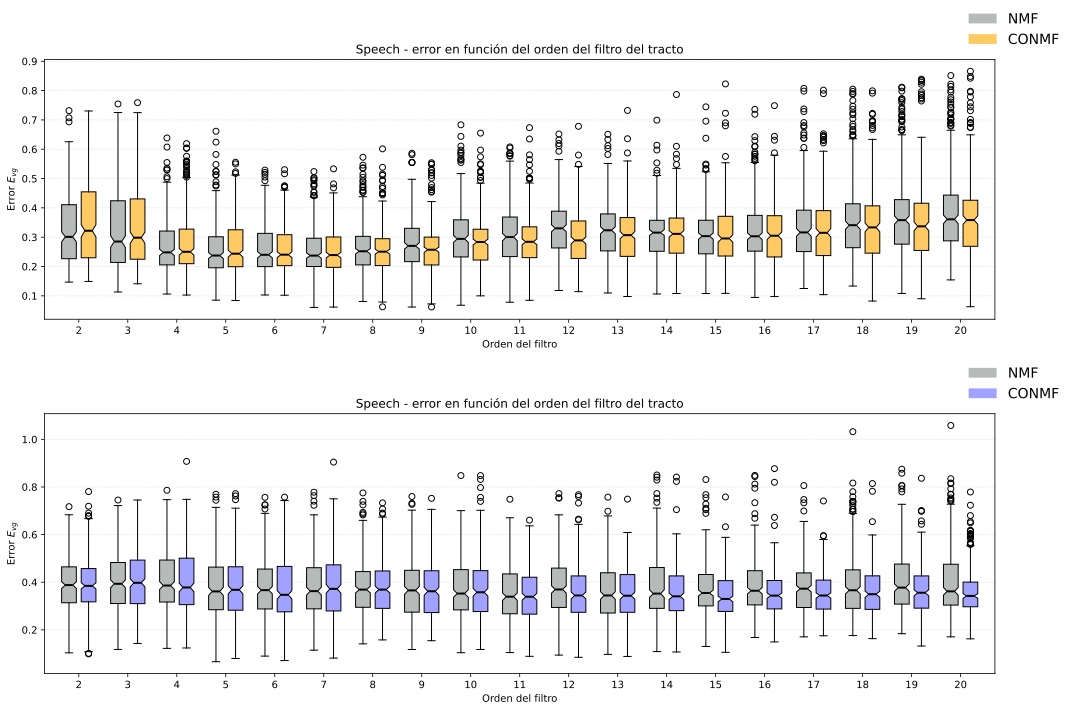

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
%config InlineBackend.figure_format = 'svg'

# ==========================================================
# Configuración
# ==========================================================
carpeta_csv = Path("Resultados boxplots/Pruebas anteriores")   # ajustá la ruta según donde estén los archivos
ordenes = list(range(2, 21))                # 2, 3, ..., 12

# ==========================================================
# Cargo los datos de cada archivo
# ==========================================================
datos_error_acc_conmf = []
datos_error_speech_conmf = []
datos_error_acc_nmf = []
datos_error_speech_nmf = []
ordenes_disponibles = []

for n in ordenes:
    #ruta = carpeta_csv / f"Orden_{n}.csv"
    ruta = carpeta_csv / f"Todas_orden_{n}.csv"
    if not ruta.exists():
        print(f"Aviso: no se encontró {ruta}, se omite orden {n}")
        continue

    df = pd.read_csv(ruta)

    datos_error_acc_conmf.append(df["CONMF_acc"].dropna().values)
    datos_error_speech_conmf.append(df["CONMF_speech"].dropna().values)
    
    datos_error_acc_nmf.append(df["NMF_acc"].dropna().values)
    datos_error_speech_nmf.append(df["NMF_speech"].dropna().values)

    ordenes_disponibles.append(n)


ordenes_labels = ordenes_disponibles                           
# ==========================================================
# Boxplot
# ==========================================================
fig, ax = plt.subplots(2,1,figsize=(15, 10))
offset = 0.2
bp = ax[0].boxplot(
    datos_error_speech_nmf,
    positions=np.array(ordenes_disponibles)-offset,
    widths=0.3,
    patch_artist=True,
    showfliers=True,
    notch=True,
)
color_nmf = "#B6BAB8"
# Color uniforme para todas las cajas
for box in bp['boxes']:
    box.set_facecolor(color_nmf)
    box.set_edgecolor("black")

for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(2)

bp2 = ax[0].boxplot(
    datos_error_speech_conmf,
    positions=np.array(ordenes_disponibles)+offset,
    widths=0.3,
    patch_artist=True,
    showfliers=True,
    notch=True,
)
color_speech = "#FFC964"

# Color uniforme para todas las cajas
for box in bp2['boxes']:
    box.set_facecolor(color_speech)
    box.set_edgecolor("black")

for median in bp2['medians']:
    median.set_color('black')
    median.set_linewidth(2)

ax[0].set_xticks(ordenes_labels)
ax[0].set_xticklabels(ordenes_labels)

ax[0].set_xlabel("Orden del filtro")
ax[0].set_ylabel(r"Error $E_{vg}$")
ax[0].set_title("Speech - error en función del orden del filtro del tracto")
ax[0].grid(axis='y', linestyle=':', alpha=0.5)


legend_elements = [
    Patch(facecolor=color_nmf, label='NMF'),
    Patch(facecolor=color_speech, label='CONMF'),
]

ax[0].legend(
    handles=legend_elements,
    loc='lower center',
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=14
)

bp3 = ax[1].boxplot(
    datos_error_acc_nmf,
    positions=np.array(ordenes_disponibles)-offset,
    widths=0.3,
    patch_artist=True,
    showfliers=True,
    notch=True,
)

# Color uniforme para todas las cajas
for box in bp3['boxes']:
    box.set_facecolor("#B6BAB8")
    box.set_edgecolor("black")

for median in bp3['medians']:
    median.set_color('black')
    median.set_linewidth(2)

bp4 = ax[1].boxplot(
    datos_error_acc_conmf,
    positions=np.array(ordenes_disponibles)+offset,
    widths=0.3,
    patch_artist=True,
    showfliers=True,
    notch=True,
)

color_acc = "#A1A1FF"
# Color uniforme para todas las cajas
for box in bp4['boxes']:
    box.set_facecolor(color_acc)
    box.set_edgecolor("black")

for median in bp4['medians']:
    median.set_color('black')
    median.set_linewidth(2)

ax[1].set_xticks(ordenes_labels)
ax[1].set_xticklabels(ordenes_labels)

ax[1].set_xlabel("Orden del filtro")
ax[1].set_ylabel(r"Error $E_{vg}$")
ax[1].set_title("Speech - error en función del orden del filtro del tracto")
ax[1].grid(axis='y', linestyle=':', alpha=0.5)


legend_elements = [
    Patch(facecolor=color_nmf, label='NMF'),
    Patch(facecolor=color_acc, label='CONMF'),
]

ax[1].legend(
    handles=legend_elements,
    loc='lower center',
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=14
)

plt.tight_layout()
plt.show()

### Efecto del orden del tracto - speech filtrado

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
%config InlineBackend.figure_format = 'svg'

# ==========================================================
# Configuración
# ==========================================================
carpeta_csv = Path("Resultados boxplots")   # ajustá la ruta según donde estén los archivos
ordenes = list(range(2, 21))                # 2, 3, ..., 12

# ==========================================================
# Cargo los datos de cada archivo
# ==========================================================
datos_error_acc_conmf = []
datos_error_speech_conmf = []
datos_error_acc_nmf = []
datos_error_speech_nmf = []
datos_error_acc_conmf_pb = []
datos_error_speech_conmf_pb = []
datos_error_acc_nmf_pb = []
datos_error_speech_nmf_pb = []
ordenes_disponibles = []
for n in ordenes:
    # Resultados sin pb
    ruta = carpeta_csv / f"2610_sin_pb_inicial_fro_orden_{n}.csv"
    df = pd.read_csv(ruta)

    datos_error_acc_conmf.append(list(df["CONMF_acc_a"].dropna())+list(df["CONMF_acc_i"].dropna()))
    datos_error_speech_conmf.append(list(df["CONMF_speech_a"].dropna())+list(df["CONMF_speech_i"].dropna()))
    
    datos_error_acc_nmf.append(list(df["NMF_acc_a"].dropna())+list(df["NMF_acc_i"].dropna()))
    datos_error_speech_nmf.append(list(df["NMF_speech_a"].dropna())+list(df["NMF_speech_i"].dropna()))

    ruta = carpeta_csv / f"2610_con_pb_inicial_fro_orden_{n}.csv"

    df = pd.read_csv(ruta)

    datos_error_acc_conmf_pb.append(list(df["CONMF_acc_a"].dropna())+list(df["CONMF_acc_i"].dropna()))
    datos_error_speech_conmf_pb.append(list(df["CONMF_speech_a"].dropna())+list(df["CONMF_speech_i"].dropna()))
    
    datos_error_acc_nmf_pb.append(list(df["NMF_acc_a"].dropna())+list(df["NMF_acc_i"].dropna()))
    datos_error_speech_nmf_pb.append(list(df["NMF_speech_a"].dropna())+list(df["NMF_speech_i"].dropna()))

    ordenes_disponibles.append(n)


ordenes_labels = ordenes_disponibles       

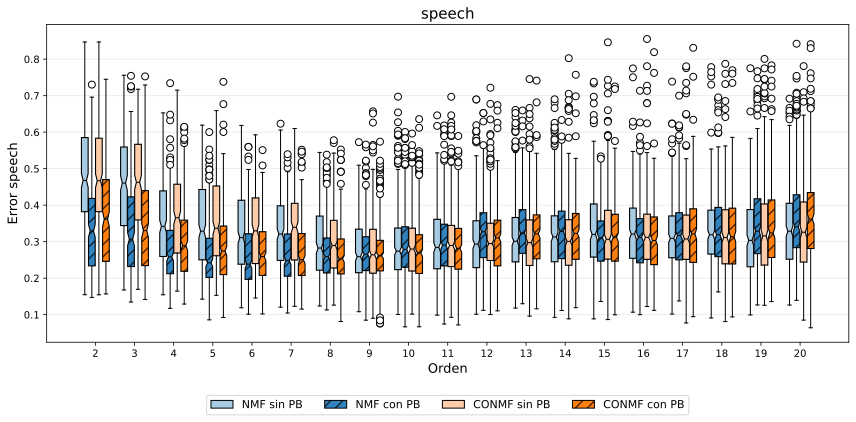

In [5]:

# ==========================================================
# Boxplots comparativos en función del orden
# ==========================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Posiciones de cada orden
posiciones = np.arange(len(ordenes_labels))
ancho = 0.18

# Desplazamientos para los cuatro boxplots
desplazamientos = [-1.5 * ancho, -0.5 * ancho,
                    0.5 * ancho,  1.5 * ancho]

# Configuración de cada conjunto de datos
series = [
    (datos_error_speech_nmf,    "NMF sin PB",    "#A6CBE3", ""),
    (datos_error_speech_nmf_pb, "NMF con PB",    "#3182BD", "//"),
    (datos_error_speech_conmf,  "CONMF sin PB",  "#FFCCAA", ""),
    (datos_error_speech_conmf_pb, "CONMF con PB", "#FF7F0E", "//"),
]

# Dibujar los cuatro grupos de boxplots
for (datos, etiqueta, color, trama), desplazamiento in zip(
        series, desplazamientos):

    bp = ax.boxplot(
        datos,
        positions=posiciones + desplazamiento,
        widths=ancho * 0.95,
        patch_artist=True,
        showfliers=True,
        notch=True,
        manage_ticks=False
    )

    # Estilo de las cajas
    for caja in bp["boxes"]:
        caja.set_facecolor(color)
        caja.set_edgecolor("black")
        caja.set_hatch(trama)
        caja.set_linewidth(1.1)

    # Estilo de medianas, bigotes y extremos
    for elemento in ("whiskers", "caps", "medians", "fliers"):
        for artista in bp[elemento]:
            artista.set_color("black")
            if elemento == "fliers":
                artista.set_marker("o")
                artista.set_markerfacecolor("white")
                artista.set_markeredgecolor("black")
                artista.set_markersize(7)

# Ejes
ax.set_xticks(posiciones)
ax.set_xticklabels(ordenes_labels)
ax.set_xlabel("Orden", fontsize=13)
ax.set_ylabel("Error speech", fontsize=13)
ax.set_title("speech", fontsize=15)

# Cuadrícula horizontal
ax.grid(axis="y", linestyle="-", alpha=0.3)
ax.set_axisbelow(True)

# Leyenda
leyenda = [
    Patch(facecolor=color, edgecolor="black",
          hatch=trama, label=etiqueta)
    for _, etiqueta, color, trama in series
]

ax.legend(
    handles=leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=4,
    frameon=True,
    fontsize=11
)

plt.tight_layout()
plt.show()


In [6]:
df = pd.read_csv("Resultados boxplots/Prueba_orden_8.csv")
df.describe()

,NMF_speech,CONMF_speech,NMF_acc,CONMF_acc
count,282.000000,282.000000,282.000000,282.000000
mean,0.245774,0.252518,0.354312,0.356843
std,0.067706,0.067624,0.103035,0.107228
min,0.084725,0.097952,0.133346,0.117606
25%,0.202353,0.217910,0.296471,0.291179
50%,0.247281,0.252260,0.349409,0.349559
75%,0.289779,0.297513,0.422137,0.430640
max,0.446049,0.456175,0.713335,0.755490


In [7]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests

df = pd.read_csv("Resultados boxplots/Prueba_orden_8.csv")

comparaciones = [("NMF_speech", "CONMF_speech"),
                 ("NMF_acc", "CONMF_acc")]

filas = []
for a, b in comparaciones:
    x, y = df[a], df[b]
    d = x - y

    # Normalidad de las diferencias
    p_norm = stats.shapiro(d).pvalue

    # Pruebas
    t = stats.ttest_rel(x, y)
    w = stats.wilcoxon(x, y)

    # Tamaño del efecto (d de Cohen pareado) e IC 95% de la diferencia media
    dz = d.mean() / d.std(ddof=1)
    ic = stats.t.interval(0.95, len(d)-1, loc=d.mean(), scale=stats.sem(d))

    filas.append({
        "comparación": f"{a} vs {b}",
        "media_dif": d.mean(),
        "IC95_inf": ic[0], "IC95_sup": ic[1],
        "p_shapiro": p_norm,
        "p_ttest": t.pvalue,
        "p_wilcoxon": w.pvalue,
        "d_cohen": dz,
    })

res = pd.DataFrame(filas)

# Corrección por comparaciones múltiples (Holm), sobre la prueba que elijas
res["p_wilcoxon_holm"] = multipletests(res["p_wilcoxon"], method="holm")[1]
res["p_ttest_holm"]    = multipletests(res["p_ttest"],    method="holm")[1]

print(res.round(5).to_string(index=False))

               comparación  media_dif  IC95_inf  IC95_sup  p_shapiro  p_ttest  p_wilcoxon  d_cohen  p_wilcoxon_holm  p_ttest_holm
NMF_speech vs CONMF_speech   -0.00674  -0.01116  -0.00233        0.0  0.00288     0.00546 -0.17906          0.01092       0.00576
      NMF_acc vs CONMF_acc   -0.00253  -0.00971   0.00465        0.0  0.48834     0.93575 -0.04132          0.93575       0.48834


### Pruebas estadísticas

In [8]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests

df = pd.read_csv("Resultados boxplots/Prueba_orden_8.csv")

comparaciones = [("NMF_speech", "CONMF_speech"),
                 ("NMF_acc", "CONMF_acc")]

filas = []
for a, b in comparaciones:
    x, y = df[a], df[b]
    d = x - y

    # Normalidad de las diferencias
    p_norm = stats.shapiro(d).pvalue

    # Pruebas
    t = stats.ttest_rel(x, y)
    w = stats.wilcoxon(x, y)

    # Tamaño del efecto (d de Cohen pareado) e IC 95% de la diferencia media
    dz = d.mean() / d.std(ddof=1)
    ic = stats.t.interval(0.95, len(d)-1, loc=d.mean(), scale=stats.sem(d))

    filas.append({
        "comparación": f"{a} vs {b}",
        "media_dif": d.mean(),
        "IC95_inf": ic[0], "IC95_sup": ic[1],
        "p_shapiro": p_norm,
        "p_ttest": t.pvalue,
        "p_wilcoxon": w.pvalue,
        "d_cohen": dz,
    })

res = pd.DataFrame(filas)

# Corrección por comparaciones múltiples (Holm), sobre la prueba que elijas
res["p_wilcoxon_holm"] = multipletests(res["p_wilcoxon"], method="holm")[1]
res["p_ttest_holm"]    = multipletests(res["p_ttest"],    method="holm")[1]

print(res.round(5).to_string(index=False))

               comparación  media_dif  IC95_inf  IC95_sup  p_shapiro  p_ttest  p_wilcoxon  d_cohen  p_wilcoxon_holm  p_ttest_holm
NMF_speech vs CONMF_speech   -0.00674  -0.01116  -0.00233        0.0  0.00288     0.00546 -0.17906          0.01092       0.00576
      NMF_acc vs CONMF_acc   -0.00253  -0.00971   0.00465        0.0  0.48834     0.93575 -0.04132          0.93575       0.48834


In [9]:
import numpy as np
from scipy import stats
import pandas as pd

df = pd.read_csv("Resultados boxplots/Prueba_orden_8.csv")

comparaciones = [("NMF_speech", "CONMF_speech"),
                 ("NMF_acc", "CONMF_acc")]

# p-valores originales (Wilcoxon pareado)
p_vals = [stats.wilcoxon(df[a], df[b]).pvalue for a, b in comparaciones]

m = len(p_vals)
p_bonf = np.minimum(np.array(p_vals) * m, 1.0)   # se limita a 1

for (a, b), p, pb in zip(comparaciones, p_vals, p_bonf):
    print(f"{a} vs {b}: p = {p:.6f} | p Bonferroni = {pb:.6f} | significativo: {pb < 0.05}")

NMF_speech vs CONMF_speech: p = 0.005460 | p Bonferroni = 0.010921 | significativo: True
NMF_acc vs CONMF_acc: p = 0.935747 | p Bonferroni = 1.000000 | significativo: False


In [10]:
print(res.round(5).to_string(index=False))

               comparación  media_dif  IC95_inf  IC95_sup  p_shapiro  p_ttest  p_wilcoxon  d_cohen  p_wilcoxon_holm  p_ttest_holm
NMF_speech vs CONMF_speech   -0.00674  -0.01116  -0.00233        0.0  0.00288     0.00546 -0.17906          0.01092       0.00576
      NMF_acc vs CONMF_acc   -0.00253  -0.00971   0.00465        0.0  0.48834     0.93575 -0.04132          0.93575       0.48834


### Pruebas del efecto del filtro pb